# Routing before and after window shortening

Each check only needs to move between its first and last data interaction (its window). `shorten_windows` greedily removes the moves outside the window and accepts a change only if every check still meets the same data qubits at the same time, in the spirit of the trace pruning in arXiv:2606.19482. Here we compare qubit and gate counts and the layouts before and after.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import directional_tile_codes as dtc

WORD, M, N = "NESEN", 4, 4
ORDER = "shortest"
code = dtc.DirectionalTileCode(M, N, dtc.DirectionalWord(WORD))
before = dtc.PhysicalLayout(code)
after = dtc.PhysicalLayout(code)
after.shorten_windows(order=ORDER)
for layout in (before, after):
    assert layout.reference == layout.trace_routes(layout.routes)[3]
    circuit, _ = layout.syndrom_extraction()
    circuit.detector_error_model()
print("Both circuit detector error models are deterministic.")

Both circuit detector error models are deterministic.


## Counts
Number of qubits, check moves and gates per round, before and after the optimization.

In [5]:
counts = pd.DataFrame({"before": before.routing_counts(), "after": after.routing_counts()})
counts["reduction"] = counts["before"] - counts["after"]
display(counts)

,before,after,reduction
data,50,50,0
checks,48,48,0
routing,48,32,16
physical,146,130,16
check_moves_per_pass,240,208,32
check_data,400,400,0
check_routing,80,16,64
data_routing,100,100,0
SWAP,180,116,64
CXSWAP,400,400,0


## Visualization
Physical layouts before and after; removed routing sites are highlighted.

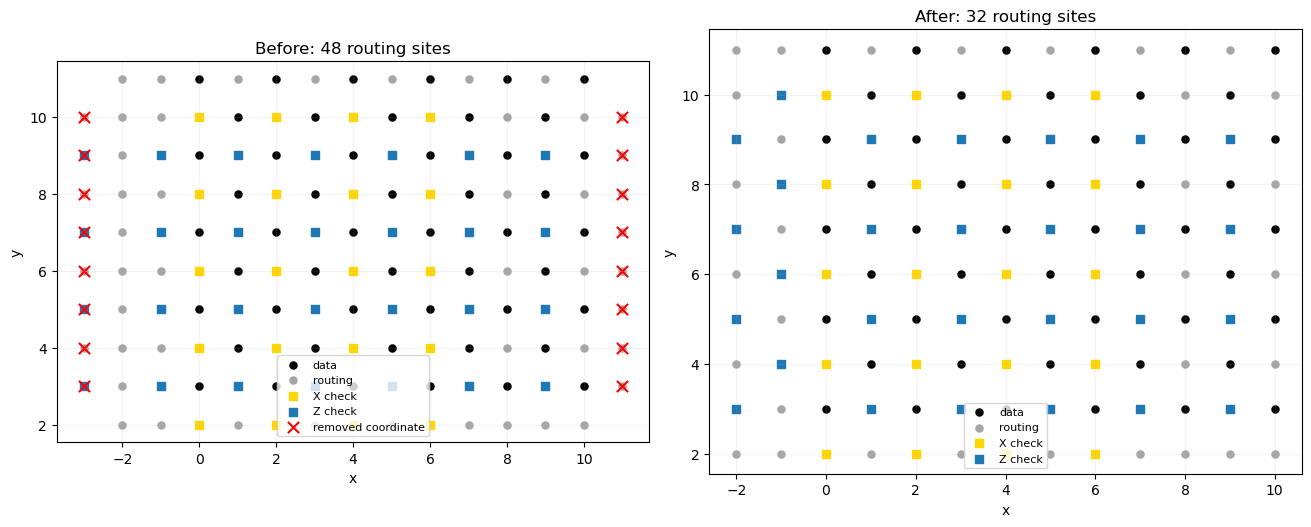

In [6]:
STYLE = {dtc.SiteType.DATA: ("black", "o", "data"),
         dtc.SiteType.ROUTING: ("0.65", "o", "routing"),
         dtc.SiteType.X_CHECK: ("gold", "s", "X check"),
         dtc.SiteType.Z_CHECK: ("tab:blue", "s", "Z check")}
def draw_sites(ax, sites):
    for kind, (color, marker, label) in STYLE.items():
        points = [p for p, site in sites.items() if site.type is kind]
        if points:
            ax.scatter([p.x for p in points], [p.y for p in points],
                       c=color, marker=marker, label=label, s=26)
    ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.grid(alpha=.15)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, layout, title in zip(axes, (before, after), ("Before", "After")):
    draw_sites(ax, layout.sites)
    ax.set_title(f"{title}: {len(layout.routing_positions)} routing sites")
removed = set(before.sites) - set(after.sites)
if removed:
    axes[0].scatter([p.x for p in removed], [p.y for p in removed],
                    marker="x", c="red", s=65, label="removed coordinate")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.show()